# Notebook 02 – Huấn luyện, Tinh chỉnh và Đánh giá mô hình

**Nhóm thực hiện:** Nhóm 4 – Lớp: 68PM2 (HUCE – Mã HP: 608807)
**Thành viên:** Bình (Trưởng nhóm - XGBoost & Pipeline), Đức Anh, Hà Duy (Baseline, Logistic, k-NN), Hoàng (Tree, RF & CV), Trần Duy (Metrics, Error Analysis & SHAP)
**Đề tài 6 – Nhóm B:** Phát hiện giao dịch gian lận thẻ tín dụng. Chỉ số trọng tâm: **PR-AUC** và **Recall**.

## Nội dung
1. Thiết lập, nạp dữ liệu và lý do chọn chỉ số
2. Baseline
3. So sánh chiến lược xử lý mất cân bằng (cross-validation)
4. Thí nghiệm ablation: kỹ nghệ đặc trưng có thật sự giúp ích?
5. Tinh chỉnh siêu tham số (GridSearchCV / RandomizedSearchCV)
6. Cross-validation độc lập cho các mô hình đã tinh chỉnh và chọn mô hình tốt nhất
7. Learning Curve và Validation Curve
8. Chọn ngưỡng quyết định (chỉ từ dự đoán out-of-fold của train)
9. Đánh giá khách quan trên **tập test độc lập**
10. Phân tích lỗi (Error Analysis)
11. Vì sao mô hình tốt nhất vượt trội
12. Mức độ quan trọng đặc trưng (permutation importance, SHAP)
13. Kiểm tra độ bền theo thời gian
14. Đóng gói mô hình `.joblib` và kiểm thử hàm dự đoán
15. Kiểm toán rò rỉ dữ liệu

## Quy trình chống rò rỉ dữ liệu (tóm tắt)
* Toàn bộ lựa chọn (chiến lược mất cân bằng, siêu tham số, mô hình, ngưỡng) chỉ dựa trên **cross-validation của tập train**.
* Mọi bước học tham số (imputer, scaler, encoder, SMOTE/undersampling) nằm **trong Pipeline** nên được fit lại trên phần train của từng fold.
* **Tập test chỉ được dùng từ mục 9**, sau khi mô hình và ngưỡng đã được cố định.

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, average_precision_score, precision_recall_curve,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, StratifiedKFold,
                                     learning_curve, validation_curve)

from evaluation import CV_SCORING, bootstrap_ci, choose_threshold, compute_metrics
from fraud_pipeline import (RANDOM_STATE, RAW_FEATURES, V_COLUMNS, load_clean_split)
from model_zoo import (FAMILIES, make_baseline, make_pipeline, param_space,
                       valid_strategies)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight"})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

FIG_DIR, TAB_DIR, MODEL_DIR = Path("../reports/figures"), Path("../reports/tables"), Path("../models")
for d in (FIG_DIR, TAB_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)
C_NORMAL, C_FRAUD = "#4C78A8", "#E45756"
FAMILY_COLORS = dict(zip(["Baseline"] + FAMILIES,
                         ["#9AA0A6", "#4C78A8", "#F58518", "#54A24B", "#B279A2", "#E45756"]))


def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png")


# Dữ liệu: cùng một hàm và cùng random_state với notebook 01 nên phép chia giống hệt.
X_train, X_test, y_train, y_test = load_clean_split()
print(f"Train: {X_train.shape}, gian lận = {int(y_train.sum())}")
print(f"Test : {X_test.shape}, gian lận = {int(y_test.sum())}  (CHƯA dùng đến mục 9)")

# Chiến lược chia fold cố định, phân tầng theo nhãn.
CV_SEARCH = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)      # dùng khi chọn mô hình / tinh chỉnh
CV_FINAL = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)               # chia khác, dùng để so sánh cuối
# Trọng số lớp = số mẫu âm / số mẫu dương. Nhờ phân tầng, mỗi fold có cùng tỷ lệ này (sai khác không đáng kể).
SPW = float((y_train == 0).sum() / (y_train == 1).sum())
print(f"scale_pos_weight = {SPW:.1f}")

Train: (226980, 30), gian lận = 378
Test : (56746, 30), gian lận = 95  (CHƯA dùng đến mục 9)
scale_pos_weight = 599.5


In [2]:
def cv_evaluate(pipe, X, y, cv, name=""):
    """Cross-validation thủ công: huấn luyện lại pipeline trên từng fold train.

    Trả về (bảng chỉ số từng fold, điểm dự đoán out-of-fold).
    Chỉ số threshold-free (PR-AUC, ROC-AUC) và chỉ số tại ngưỡng 0.5 (Recall,
    Precision, F1, F2, MCC) được tính trên fold validation.
    """
    oof = np.zeros(len(y))
    rows = []
    for k, (tr, va) in enumerate(cv.split(X, y)):
        est = clone(pipe)
        t0 = time.perf_counter()
        est.fit(X.iloc[tr], y.iloc[tr])
        fit_time = time.perf_counter() - t0
        score = est.predict_proba(X.iloc[va])[:, 1]
        oof[va] = score
        m = compute_metrics(y.iloc[va], score, 0.5)
        m.update(fold=k, fit_time=fit_time)
        rows.append(m)
    return pd.DataFrame(rows), oof


def summarize(fold_df, oof, y):
    """Gộp kết quả các fold thành một dòng: trung bình và độ lệch chuẩn."""
    out = {}
    for col in ["PR-AUC", "ROC-AUC", "Recall", "Precision", "F1", "F2", "MCC"]:
        out[col] = fold_df[col].mean()
        out[col + " (std)"] = fold_df[col].std()
    # F2 tốt nhất có thể đạt được trên điểm số out-of-fold (đã chọn ngưỡng lý tưởng)
    thr = choose_threshold(y, oof, "f2")
    out["F2 @ngưỡng tối ưu (OOF)"] = compute_metrics(y, oof, thr)["F2"]
    out["Thời gian fit/fold (s)"] = fold_df["fit_time"].mean()
    return out

## 1. Lý do chọn chỉ số đánh giá

Với tỷ lệ gian lận ≈ 0,17%, **Accuracy vô nghĩa**: một mô hình "luôn đoán bình thường" đạt ≈ 99,83% mà không bắt được ca gian lận nào. Các chỉ số dùng trong notebook:

* **PR-AUC (Average Precision)**: diện tích dưới đường Precision-Recall; **chỉ số chính**, vì chỉ phụ thuộc cách mô hình xếp hạng lớp hiếm. Mô hình ngẫu nhiên có PR-AUC ≈ tỷ lệ gian lận (0,0017).
* **Recall** (độ phủ gian lận): tỷ lệ ca gian lận bị bắt. Bỏ sót gian lận gây thiệt hại trực tiếp.
* **Precision**: trong các cảnh báo, bao nhiêu phần trăm là gian lận thật; liên quan chi phí xử lý cảnh báo nhầm.
* **F2**: trung bình điều hòa nghiêng về Recall (Recall quan trọng gấp đôi Precision), phù hợp mục tiêu "tối ưu Recall".
* **ROC-AUC** và **MCC**: tham khảo. ROC-AUC dễ lạc quan khi lớp âm quá lớn; MCC cân đối cả bốn ô của ma trận nhầm lẫn.

## 2. Baseline

* **Baseline ngây thơ**: `DummyClassifier(strategy="prior")` luôn trả về tỷ lệ lớp (không dùng đặc trưng). Đây là mốc "không biết gì".
* **Baseline thực tế**: Logistic Regression mặc định (không xử lý mất cân bằng) trong cùng pipeline tiền xử lý.

Cả hai đánh giá bằng 5-fold stratified CV trên tập train.

In [3]:
baseline_models = {
    "Baseline (Dummy - prior)": make_baseline(),
    "Baseline (Logistic Regression mặc định)": make_pipeline("Logistic Regression", "none"),
}
baseline_rows, baseline_oof = {}, {}
for name, pipe in baseline_models.items():
    fold_df, oof = cv_evaluate(pipe, X_train, y_train, CV_SEARCH, name)
    baseline_rows[name] = summarize(fold_df, oof, y_train)
    baseline_oof[name] = oof
baseline_table = pd.DataFrame(baseline_rows).T
baseline_table["Accuracy (tham khảo)"] = [
    accuracy_score(y_train, (baseline_oof[n] >= 0.5).astype(int)) for n in baseline_table.index]
baseline_table.to_csv(TAB_DIR / "baseline_cv.csv")
baseline_table[["PR-AUC", "ROC-AUC", "Recall", "Precision", "F2", "Accuracy (tham khảo)"]]

,PR-AUC,ROC-AUC,Recall,Precision,F2,Accuracy (tham khảo)
Baseline (Dummy - prior),0.0017,0.5000,0.0000,0.0000,0.0000,0.9983
Baseline (Logistic Regression mặc định),0.8197,0.9806,0.7169,0.8961,0.7448,0.9994


**Nhận xét.** Dummy đạt Accuracy ≈ 99,8% nhưng PR-AUC chỉ ≈ 0,0017 và Recall = 0: minh họa rõ vì sao không dùng Accuracy. Logistic Regression mặc định (không cân bằng lớp) đã có PR-AUC cao hơn rất nhiều nhưng Recall tại ngưỡng 0,5 còn thấp, cho thấy cần xử lý mất cân bằng và chọn ngưỡng. Hai điểm này là cơ sở để so sánh mọi mô hình phía sau.

## 3. So sánh chiến lược xử lý mất cân bằng

Với mỗi họ mô hình, thử ba chiến lược, **tất cả nằm trong Pipeline** nên SMOTE/undersampling chỉ chạy trên phần train của từng fold (validation fold giữ nguyên phân phối thật):

1. **class_weight / scale_pos_weight**: tăng trọng số lỗi của lớp gian lận khi huấn luyện.
2. **SMOTE**: sinh thêm mẫu gian lận tổng hợp (nội suy giữa các lân cận) đến tỷ lệ 1:10.
3. **Random Undersampling**: giảm mẫu lớp bình thường đến tỷ lệ 1:10.

k-NN chỉ thử undersampling (không có trọng số lớp; SMOTE làm bước dự đoán quá chậm). Siêu tham số ở bước này là mặc định hợp lý; bước tinh chỉnh ở mục 5 mới tối ưu chi tiết.

In [4]:
strategy_rows, strategy_oof = [], {}
for family in FAMILIES:
    for strategy in valid_strategies(family):
        pipe = make_pipeline(family, strategy, scale_pos_weight=SPW)
        fold_df, oof = cv_evaluate(pipe, X_train, y_train, CV_SEARCH)
        strategy_rows.append({"Mô hình": family, "Chiến lược": strategy, **summarize(fold_df, oof, y_train)})
        strategy_oof[(family, strategy)] = oof
        print(f"{family:20s} {strategy:15s} PR-AUC = {strategy_rows[-1]['PR-AUC']:.4f}  "
              f"Recall@0.5 = {strategy_rows[-1]['Recall']:.3f}  ({strategy_rows[-1]['Thời gian fit/fold (s)']:.1f}s/fold)", flush=True)

strategy_table = pd.DataFrame(strategy_rows)
strategy_table.to_csv(TAB_DIR / "imbalance_strategy_comparison.csv", index=False)
strategy_table[["Mô hình", "Chiến lược", "PR-AUC", "PR-AUC (std)", "ROC-AUC", "Recall", "Precision",
                "F2", "F2 @ngưỡng tối ưu (OOF)", "Thời gian fit/fold (s)"]]

Logistic Regression  class_weight    PR-AUC = 0.7686  Recall@0.5 = 0.915  (2.3s/fold)


Logistic Regression  SMOTE           PR-AUC = 0.8015  Recall@0.5 = 0.862  (2.3s/fold)


Logistic Regression  Undersampling   PR-AUC = 0.7575  Recall@0.5 = 0.860  (0.9s/fold)


k-NN                 Undersampling   PR-AUC = 0.6450  Recall@0.5 = 0.855  (0.9s/fold)


Decision Tree        class_weight    PR-AUC = 0.4181  Recall@0.5 = 0.831  (6.1s/fold)


Decision Tree        SMOTE           PR-AUC = 0.6715  Recall@0.5 = 0.836  (7.7s/fold)


... (4 outputs left out)

XGBoost              class_weight    PR-AUC = 0.8497  Recall@0.5 = 0.831  (6.8s/fold)


XGBoost              SMOTE           PR-AUC = 0.8429  Recall@0.5 = 0.823  (7.2s/fold)


XGBoost              Undersampling   PR-AUC = 0.7876  Recall@0.5 = 0.865  (1.4s/fold)


,Mô hình,Chiến lược,PR-AUC,PR-AUC (std),ROC-AUC,Recall,Precision,F2,F2 @ngưỡng tối ưu (OOF),Thời gian fit/fold (s)
0,Logistic Regression,class_weight,0.7686,0.0452,0.9807,0.9153,0.0538,0.2172,0.7956,2.2682
1,Logistic Regression,SMOTE,0.8015,0.0346,0.9793,0.8624,0.3803,0.6871,0.8021,2.3162
2,Logistic Regression,Undersampling,0.7575,0.0599,0.9823,0.8597,0.3438,0.6596,0.7975,0.9151
3,k-NN,Undersampling,0.6450,0.0639,0.9494,0.8545,0.4992,0.7463,0.7936,0.9461
4,Decision Tree,class_weight,0.4181,0.1430,0.9159,0.8308,0.1439,0.4160,0.6906,6.1082
5,Decision Tree,SMOTE,0.6715,0.0272,0.9335,0.8358,0.4354,0.7024,0.8153,7.7048
6,Decision Tree,Undersampling,0.3730,0.0574,0.9418,0.8810,0.1532,0.4305,0.6936,0.9922
7,Random Forest,class_weight,0.8284,0.0389,0.9530,0.7619,0.9004,0.7852,0.8285,28.1309
8,Random Forest,SMOTE,0.8460,0.0350,0.9824,0.8386,0.8291,0.8357,0.8396,53.5479
9,Random Forest,Undersampling,0.7627,0.0407,0.9695,0.8492,0.5612,0.7683,0.8094,1.3464


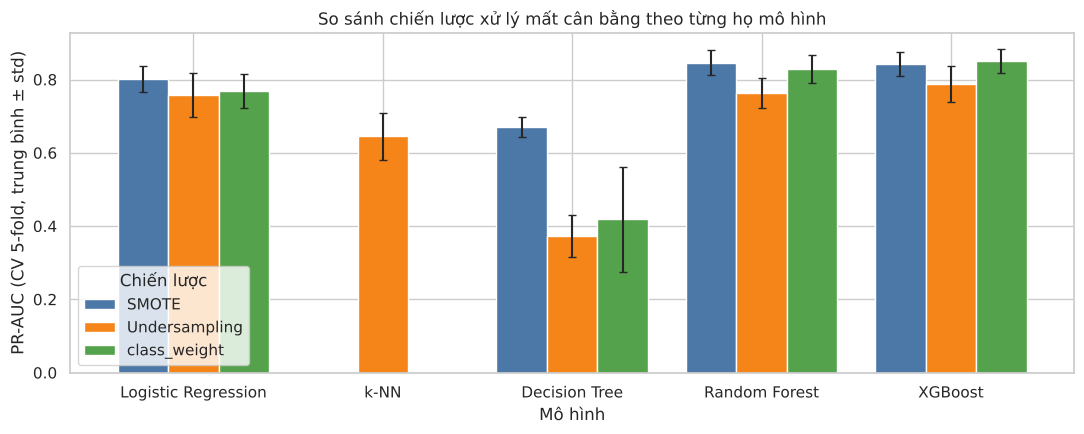

Chiến lược tốt nhất theo PR-AUC (CV) cho từng họ mô hình:
Mô hình
Logistic Regression            SMOTE
k-NN                   Undersampling
Decision Tree                  SMOTE
Random Forest                  SMOTE
XGBoost                 class_weight


In [5]:
fig, ax = plt.subplots(figsize=(11, 4.5))
pivot = strategy_table.pivot(index="Mô hình", columns="Chiến lược", values="PR-AUC").reindex(FAMILIES)
err = strategy_table.pivot(index="Mô hình", columns="Chiến lược", values="PR-AUC (std)").reindex(FAMILIES)
pivot.plot.bar(ax=ax, yerr=err, capsize=3, width=0.8, color=["#4C78A8", "#F58518", "#54A24B"])
ax.set(ylabel="PR-AUC (CV 5-fold, trung bình ± std)", title="So sánh chiến lược xử lý mất cân bằng theo từng họ mô hình")
ax.legend(title="Chiến lược")
plt.xticks(rotation=0)
plt.tight_layout()
save_fig("10_imbalance_strategy_comparison")
plt.show()

# Chọn chiến lược tốt nhất cho từng họ mô hình theo PR-AUC trung bình của CV (không dùng test).
best_strategy = (strategy_table.sort_values("PR-AUC", ascending=False)
                 .groupby("Mô hình").first()["Chiến lược"].reindex(FAMILIES))
print("Chiến lược tốt nhất theo PR-AUC (CV) cho từng họ mô hình:")
print(best_strategy.to_string())

**Nhận xét (mục 3).** * **Accuracy không có giá trị phân biệt**: mô hình Dummy chỉ cần luôn đoán "bình thường" đã đạt 99,83% accuracy nhưng PR-AUC chỉ 0,0017 và Recall = 0. Vì vậy mọi so sánh dưới đây dùng PR-AUC (không phụ thuộc ngưỡng) cùng Recall/Precision/F2.
* **Baseline Logistic Regression mặc định** (không xử lý mất cân bằng) đã đạt PR-AUC 0,820 nhưng Recall@0,5 chỉ 0,717: mô hình *xếp hạng* khá tốt nhưng ngưỡng 0,5 bỏ sót nhiều ca gian lận.
* **Nhóm cây tập hợp (Random Forest, XGBoost) cho PR-AUC cao nhất** (0,83 - 0,85 ở cấu hình mặc định). XGBoost cho cân bằng tốt giữa Recall (~0,83) và Precision (~0,89); `class_weight` và SMOTE cho kết quả gần như tương đương (0,850 so với 0,843, chênh lệch nhỏ hơn độ lệch chuẩn giữa các fold ~0,033).
* **Với Logistic Regression, các kỹ thuật cân bằng chủ yếu dịch chuyển điểm vận hành chứ không cải thiện khả năng xếp hạng**: Recall@0,5 tăng (0,72 lên 0,86 - 0,92) nhưng Precision tụt mạnh (với `class_weight="balanced"` chỉ còn 0,054), còn PR-AUC không cao hơn baseline. Do đó cần chọn *ngưỡng* một cách có chủ đích (mục 8) thay vì chỉ trông vào cột "@0,5".
* **Undersampling là chiến lược yếu nhất cho PR-AUC ở các mô hình cây** (Decision Tree 0,373; Random Forest 0,763) vì vứt bỏ phần lớn mẫu bình thường; nó chỉ có ý nghĩa với k-NN (vốn không có tham số trọng số lớp, và để tìm lân cận trên toàn bộ dữ liệu thì rất chậm).
* **Decision Tree đơn lẻ có phương sai cao** (độ lệch chuẩn PR-AUC giữa các fold lên tới 0,14 với `class_weight`) và Precision thấp, đúng như kỳ vọng với một cây không được cắt tỉa mạnh.
* Chiến lược tốt nhất cho từng họ mô hình (theo PR-AUC CV) được đem đi tinh chỉnh ở mục 5: LR - SMOTE, k-NN - Undersampling, Decision Tree - SMOTE, Random Forest - SMOTE, XGBoost - `class_weight`.

## 4. Ablation: kỹ nghệ đặc trưng có thật sự giúp ích?

So sánh hai pipeline giống hệt nhau ở mọi thứ khác, chỉ khác đầu vào: **đặc trưng gốc** (V1-V28 và Amount) và **đặc trưng đã kỹ nghệ** (mục 6 notebook 01). Dùng cùng các fold, chiến lược tốt nhất của từng họ mô hình, và so sánh theo từng fold (paired).

In [6]:
ablation_rows = []
for family in FAMILIES:
    strat = best_strategy[family]
    per_variant = {}
    for label, fe_flag in [("Đặc trưng gốc", False), ("Đặc trưng kỹ nghệ", True)]:
        pipe = make_pipeline(family, strat, scale_pos_weight=SPW, feature_engineering=fe_flag)
        fold_df, _ = cv_evaluate(pipe, X_train, y_train, CV_SEARCH)
        per_variant[label] = fold_df
    diff = per_variant["Đặc trưng kỹ nghệ"]["PR-AUC"] - per_variant["Đặc trưng gốc"]["PR-AUC"]
    ablation_rows.append({
        "Mô hình": family, "Chiến lược": strat,
        "PR-AUC (gốc)": per_variant["Đặc trưng gốc"]["PR-AUC"].mean(),
        "PR-AUC (kỹ nghệ)": per_variant["Đặc trưng kỹ nghệ"]["PR-AUC"].mean(),
        "Chênh lệch TB": diff.mean(), "Chênh lệch std": diff.std(),
        "Số fold cải thiện": int((diff > 0).sum()),
        "Recall@0.5 (gốc)": per_variant["Đặc trưng gốc"]["Recall"].mean(),
        "Recall@0.5 (kỹ nghệ)": per_variant["Đặc trưng kỹ nghệ"]["Recall"].mean(),
    })
    print(family, "xong", flush=True)
ablation = pd.DataFrame(ablation_rows)
ablation.to_csv(TAB_DIR / "ablation_feature_engineering.csv", index=False)
ablation

Logistic Regression xong


k-NN xong


Decision Tree xong


Random Forest xong


XGBoost xong


,Mô hình,Chiến lược,PR-AUC (gốc),PR-AUC (kỹ nghệ),Chênh lệch TB,Chênh lệch std,Số fold cải thiện,Recall@0.5 (gốc),Recall@0.5 (kỹ nghệ)
0,Logistic Regression,SMOTE,0.7561,0.8015,0.0453,0.0269,5,0.8624,0.8624
1,k-NN,Undersampling,0.6238,0.6450,0.0212,0.0280,4,0.8466,0.8545
2,Decision Tree,SMOTE,0.6383,0.6715,0.0332,0.0456,4,0.8093,0.8358
3,Random Forest,SMOTE,0.8448,0.8460,0.0011,0.0088,3,0.8386,0.8386
4,XGBoost,class_weight,0.8473,0.8497,0.0024,0.0051,3,0.8307,0.8306


**Nhận xét (mục 4).** Kỹ nghệ đặc trưng (log-Amount, cờ giao dịch nhỏ, Hour/chu kỳ sin-cos, nhóm thời điểm, chuẩn V, tương tác giữa các thành phần V14/V12/V10/V17) được so sánh trực tiếp với cùng pipeline chỉ dùng cột gốc, trên **cùng các fold**.

* Với mô hình tuyến tính/khoảng cách/một cây đơn, đặc trưng mới có xu hướng *có ích*: PR-AUC tăng +0,045 (Logistic Regression, cải thiện ở 5/5 fold), +0,033 (Decision Tree, 4/5 fold) và +0,021 (k-NN, 4/5 fold). Điều này hợp lý vì các mô hình này không tự học được tương tác phi tuyến giữa các biến.
* Với **Random Forest và XGBoost mức cải thiện gần như bằng 0** (+0,001 và +0,002, nhỏ hơn nhiều so với độ lệch chuẩn giữa các fold), vì cây tự khám phá tương tác.
* Trung thực mà nói, chỉ riêng Logistic Regression có cải thiện nhất quán ở mọi fold; với các mô hình còn lại, chênh lệch nằm trong khoảng nhiễu của CV nên không nên khẳng định kỹ nghệ đặc trưng "chắc chắn" giúp ích. Pipeline vẫn giữ các đặc trưng này vì chúng không gây hại và có lợi cho các mô hình đơn giản hơn (cũng là điều kiện của đề bài).
* Các đặc trưng được tính **không có trạng thái** (chỉ từ chính từng dòng), nên không thể gây rò rỉ dữ liệu.

## 5. Tinh chỉnh siêu tham số

Mỗi họ mô hình được tinh chỉnh với **chiến lược mất cân bằng tốt nhất** ở mục 3, theo `scoring="average_precision"` (PR-AUC), 5-fold stratified CV trên tập train:
* `GridSearchCV`: Logistic Regression, k-NN (không gian nhỏ, quét toàn bộ).
* `RandomizedSearchCV`: Decision Tree, Random Forest, XGBoost (không gian lớn, lấy mẫu ngẫu nhiên).

Do `Pipeline` bao toàn bộ bước tiền xử lý, imputer, scaler, encoder và sampler được fit lại trên từng fold train trong quá trình tìm kiếm, không có thông tin của fold validation hay của tập test lọt vào.

> Điểm `best_score_` của search là điểm trên chính các fold đã dùng để chọn nên hơi lạc quan. Vì vậy mục 6 đánh giá lại các mô hình đã tinh chỉnh bằng một phép chia fold khác, và mục 9 dùng tập test độc lập.

In [7]:
N_ITER = {"Decision Tree": 15, "Random Forest": 12, "XGBoost": 25}
searches, tuning_rows = {}, []
for family in FAMILIES:
    strat = best_strategy[family]
    pipe = make_pipeline(family, strat, scale_pos_weight=SPW, n_jobs=1)
    space, kind = param_space(family, strat, SPW)
    common = dict(scoring="average_precision", cv=CV_SEARCH, n_jobs=2, refit=True, return_train_score=False)
    if kind == "grid":
        search = GridSearchCV(pipe, space, **common)
    else:
        search = RandomizedSearchCV(pipe, space, n_iter=N_ITER[family], random_state=RANDOM_STATE, **common)
    t0 = time.perf_counter()
    search.fit(X_train, y_train)
    elapsed = time.perf_counter() - t0
    searches[family] = search
    pd.DataFrame(search.cv_results_).drop(columns=["params"]).to_csv(
        TAB_DIR / f"tuning_results_{family.replace(' ', '_').replace('-', '')}.csv", index=False)
    tuning_rows.append({
        "Mô hình": family, "Chiến lược": strat,
        "Phương pháp": "GridSearchCV" if kind == "grid" else f"RandomizedSearchCV (n_iter={N_ITER[family]})",
        "Số tổ hợp": len(search.cv_results_["params"]),
        "PR-AUC tốt nhất (CV)": search.best_score_,
        "Thời gian (phút)": elapsed / 60,
        "Siêu tham số tốt nhất": json.dumps(
            {k.split("__", 1)[1] if "__" in k else k: (v if not isinstance(v, np.generic) else v.item())
             for k, v in search.best_params_.items()}, ensure_ascii=False, default=str),
    })
    print(f"{family:20s} best CV PR-AUC = {search.best_score_:.4f}  ({elapsed/60:.1f} phút)", flush=True)

tuning_table = pd.DataFrame(tuning_rows)
tuning_table.to_csv(TAB_DIR / "hyperparameter_tuning_summary.csv", index=False)
tuning_table

Logistic Regression  best CV PR-AUC = 0.8032  (1.9 phút)


k-NN                 best CV PR-AUC = 0.7736  (3.7 phút)


Decision Tree        best CV PR-AUC = 0.7581  (5.0 phút)


Random Forest        best CV PR-AUC = 0.8445  (48.7 phút)


XGBoost              best CV PR-AUC = 0.8542  (6.8 phút)


,Mô hình,Chiến lược,Phương pháp,Số tổ hợp,PR-AUC tốt nhất (CV),Thời gian (phút),Siêu tham số tốt nhất
0,Logistic Regression,SMOTE,GridSearchCV,18,0.8032,1.9170,"{""C"": 0.01, ""sampling_strategy"": 0.05}"
1,k-NN,Undersampling,GridSearchCV,40,0.7736,3.6740,"{""n_neighbors"": 41, ""weights"": ""distance"", ""sa..."
2,Decision Tree,SMOTE,RandomizedSearchCV (n_iter=15),15,0.7581,4.9809,"{""sampling_strategy"": 0.3, ""min_samples_leaf"":..."
3,Random Forest,SMOTE,RandomizedSearchCV (n_iter=12),12,0.8445,48.7420,"{""sampling_strategy"": 0.05, ""n_estimators"": 30..."
4,XGBoost,class_weight,RandomizedSearchCV (n_iter=25),25,0.8542,6.8091,"{""subsample"": 0.7, ""scale_pos_weight"": 10, ""re..."


In [8]:
for family in FAMILIES:
    print(f"{family}: {searches[family].best_params_}")

Logistic Regression: {'model__C': 0.01, 'sampler__sampling_strategy': 0.05}
k-NN: {'model__n_neighbors': 41, 'model__weights': 'distance', 'sampler__sampling_strategy': 0.02}
Decision Tree: {'sampler__sampling_strategy': 0.3, 'model__min_samples_leaf': 50, 'model__max_depth': 8, 'model__criterion': 'entropy'}
Random Forest: {'sampler__sampling_strategy': 0.05, 'model__n_estimators': 300, 'model__min_samples_leaf': 10, 'model__max_samples': 0.4, 'model__max_features': 0.3, 'model__max_depth': 12}
XGBoost: {'model__subsample': 0.7, 'model__scale_pos_weight': 10, 'model__reg_lambda': 1, 'model__n_estimators': 300, 'model__min_child_weight': 3, 'model__max_depth': 8, 'model__learning_rate': 0.05, 'model__gamma': 1, 'model__colsample_bytree': 0.6}


## 6. Cross-validation độc lập cho các mô hình đã tinh chỉnh

Mỗi pipeline tốt nhất của mục 5 được đánh giá lại bằng **5-fold stratified CV với phép chia khác** (`random_state=2024`) trên tập train. Kết quả này được dùng để (a) lập bảng so sánh chính thức, (b) chọn mô hình tốt nhất, (c) lấy dự đoán out-of-fold để chọn ngưỡng ở mục 8.

In [9]:
final_cv_rows, oof_scores, fold_tables = [], {}, {}
# Đưa baseline vào cùng bảng để có mốc so sánh
fold_df, oof = cv_evaluate(make_baseline(), X_train, y_train, CV_FINAL)
final_cv_rows.append({"Mô hình": "Baseline (Dummy)", **summarize(fold_df, oof, y_train)})
oof_scores["Baseline (Dummy)"], fold_tables["Baseline (Dummy)"] = oof, fold_df

for family in FAMILIES:
    pipe = clone(searches[family].best_estimator_)  # cấu hình đã tinh chỉnh, chưa fit
    fold_df, oof = cv_evaluate(pipe, X_train, y_train, CV_FINAL)
    final_cv_rows.append({"Mô hình": family, **summarize(fold_df, oof, y_train)})
    oof_scores[family], fold_tables[family] = oof, fold_df
    print(f"{family:20s} PR-AUC = {final_cv_rows[-1]['PR-AUC']:.4f} ± {final_cv_rows[-1]['PR-AUC (std)']:.4f}", flush=True)

cv_table = pd.DataFrame(final_cv_rows).set_index("Mô hình")
cv_table.to_csv(TAB_DIR / "cv_comparison_tuned_models.csv")
cols = ["PR-AUC", "PR-AUC (std)", "ROC-AUC", "Recall", "Precision", "F1", "F2", "MCC",
        "F2 @ngưỡng tối ưu (OOF)", "Thời gian fit/fold (s)"]
cv_table[cols]

Logistic Regression  PR-AUC = 0.8098 ± 0.0230


k-NN                 PR-AUC = 0.7642 ± 0.0444


Decision Tree        PR-AUC = 0.7273 ± 0.0294


Random Forest        PR-AUC = 0.8501 ± 0.0167


XGBoost              PR-AUC = 0.8572 ± 0.0149


,PR-AUC,PR-AUC (std),ROC-AUC,Recall,Precision,F1,F2,MCC,F2 @ngưỡng tối ưu (OOF),Thời gian fit/fold (s)
Mô hình,,,,,,,,,,
Baseline (Dummy),0.0017,0.0000,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0083,0.8827
Logistic Regression,0.8098,0.0230,0.9822,0.8546,0.6665,0.7473,0.8076,0.7534,0.8134,1.3683
k-NN,0.7642,0.0444,0.9606,0.7725,0.8208,0.7944,0.7808,0.7952,0.8154,0.8639
Decision Tree,0.7273,0.0294,0.9320,0.8466,0.1460,0.2463,0.4232,0.3457,0.7919,9.0197
Random Forest,0.8501,0.0167,0.9829,0.8333,0.7815,0.8038,0.8205,0.8052,0.8351,249.0437
XGBoost,0.8572,0.0149,0.9832,0.8280,0.9196,0.8707,0.8445,0.8721,0.8468,7.1548


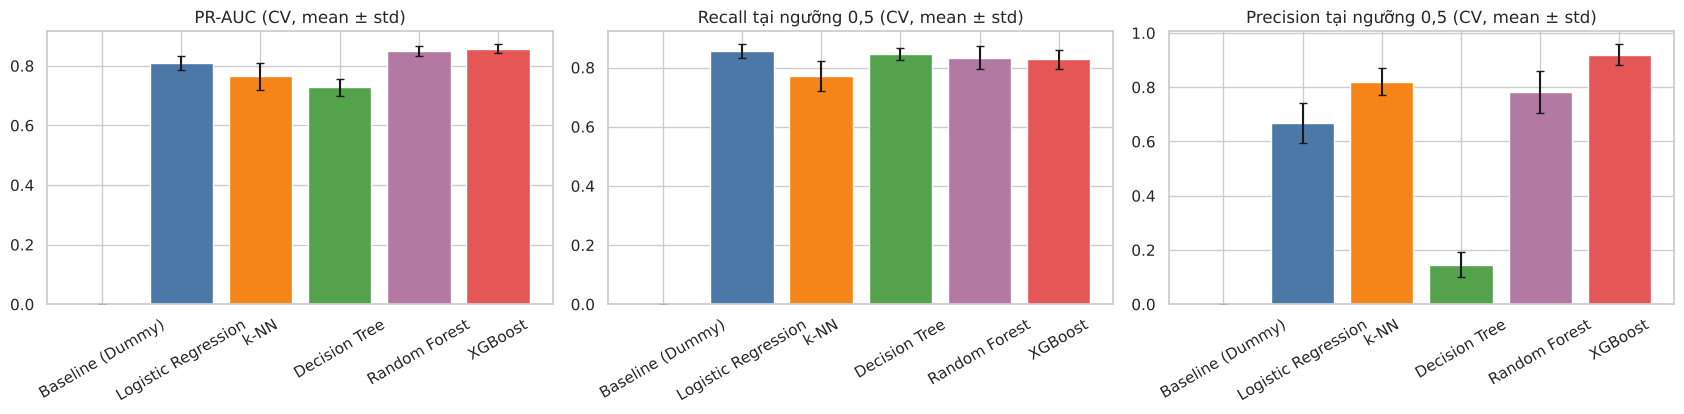

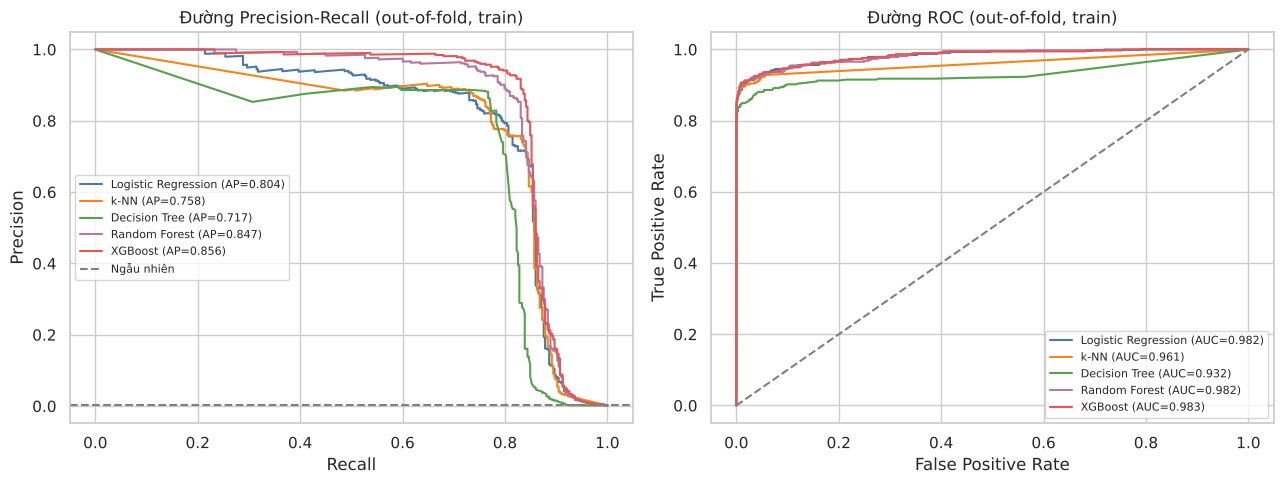

In [10]:
# Biểu đồ so sánh PR-AUC / Recall giữa các mô hình (trung bình ± std qua 5 fold)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
order = cv_table.index.tolist()
for ax, metric, title in zip(axes, ["PR-AUC", "Recall", "Precision"],
                              ["PR-AUC", "Recall tại ngưỡng 0,5", "Precision tại ngưỡng 0,5"]):
    ax.bar(order, cv_table[metric], yerr=cv_table[metric + " (std)"], capsize=3,
           color=[FAMILY_COLORS.get(n.split(" (")[0], "#9AA0A6") for n in order])
    ax.set_title(f"{title} (CV, mean ± std)")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
save_fig("11_cv_model_comparison")
plt.show()

# Đường PR và ROC tổng hợp từ điểm out-of-fold của tập train
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, oof in oof_scores.items():
    if name.startswith("Baseline"):
        continue
    p, r, _ = precision_recall_curve(y_train, oof)
    fpr, tpr, _ = roc_curve(y_train, oof)
    ap, auc = average_precision_score(y_train, oof), roc_auc_score(y_train, oof)
    axes[0].plot(r, p, label=f"{name} (AP={ap:.3f})", color=FAMILY_COLORS[name])
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})", color=FAMILY_COLORS[name])
axes[0].axhline(y_train.mean(), color="gray", ls="--", label="Ngẫu nhiên")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Đường Precision-Recall (out-of-fold, train)")
axes[1].plot([0, 1], [0, 1], color="gray", ls="--")
axes[1].set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="Đường ROC (out-of-fold, train)")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
save_fig("12_cv_pr_roc_curves")
plt.show()

In [11]:
# Chọn mô hình tốt nhất theo PR-AUC trung bình của CV (chỉ số chính của đề tài). KHÔNG dùng test.
candidates = cv_table.drop(index="Baseline (Dummy)")
BEST_FAMILY = candidates["PR-AUC"].idxmax()
best_row = candidates.loc[BEST_FAMILY]
runner_up = candidates["PR-AUC"].drop(BEST_FAMILY).idxmax()
print(f"Mô hình tốt nhất theo CV: {BEST_FAMILY}  (PR-AUC = {best_row['PR-AUC']:.4f} ± {best_row['PR-AUC (std)']:.4f})")
print(f"Á quân: {runner_up}  (PR-AUC = {candidates.loc[runner_up, 'PR-AUC']:.4f} ± {candidates.loc[runner_up, 'PR-AUC (std)']:.4f})")

# Kiểm tra thêm: trong từng fold, mô hình tốt nhất có thắng á quân không?
paired = fold_tables[BEST_FAMILY]["PR-AUC"] - fold_tables[runner_up]["PR-AUC"]
print(f"Chênh lệch PR-AUC theo từng fold (tốt nhất - á quân): {np.round(paired.values, 4)}")
print(f"Số fold thắng: {(paired > 0).sum()}/5")

Mô hình tốt nhất theo CV: XGBoost  (PR-AUC = 0.8572 ± 0.0149)
Á quân: Random Forest  (PR-AUC = 0.8501 ± 0.0167)
Chênh lệch PR-AUC theo từng fold (tốt nhất - á quân): [ 0.0068  0.0032  0.0158 -0.0012  0.0107]
Số fold thắng: 4/5


**Nhận xét (mục 6).** * Kết quả tinh chỉnh (5-fold, `average_precision`): XGBoost 0,854 (RandomizedSearchCV 25 tổ hợp), Random Forest 0,845, Logistic Regression 0,803, Decision Tree 0,758, k-NN 0,774. Tuning cải thiện đáng kể cho k-NN (0,645 lên 0,774) và Decision Tree (0,672 lên 0,758), nhưng chỉ cải thiện rất ít cho XGBoost và Random Forest (đã gần trần).
* Bảng so sánh cuối cùng dùng **một phép chia CV khác** (seed 2024, độc lập với phép chia dùng khi tinh chỉnh) nhằm giảm thiên lệch lạc quan do tuning. **XGBoost đạt PR-AUC 0,857 ± 0,015, đứng đầu về PR-AUC, F1 (0,871), F2 và MCC** và thắng Random Forest ở 4/5 fold; chênh lệch với Random Forest (0,007) nhỏ so với độ lệch chuẩn nên về mặt thống kê hai mô hình *ngang nhau* (xem mục 11).
* XGBoost còn nhanh hơn Random Forest rất nhiều khi huấn luyện (~7 giây so với ~249 giây mỗi fold), nên là lựa chọn thực dụng hơn.
* Decision Tree có Recall cao (0,85) nhưng Precision chỉ 0,146 ở ngưỡng 0,5, tức là đưa ra rất nhiều cảnh báo nhầm; Logistic Regression cân bằng hơn (Recall 0,85, Precision 0,67) nhưng PR-AUC thấp hơn các mô hình cây.

## 7. Learning Curve và Validation Curve (mô hình tốt nhất)

* **Learning curve**: PR-AUC của train và validation khi tăng dần lượng dữ liệu huấn luyện, để chẩn đoán overfitting/underfitting và xem thêm dữ liệu có giúp ích không.
* **Validation curve**: PR-AUC theo một siêu tham số quan trọng, giữ nguyên các tham số khác ở giá trị đã tinh chỉnh.

Cả hai chỉ chạy trên tập train bằng cross-validation (pipeline đầy đủ, nên không rò rỉ).

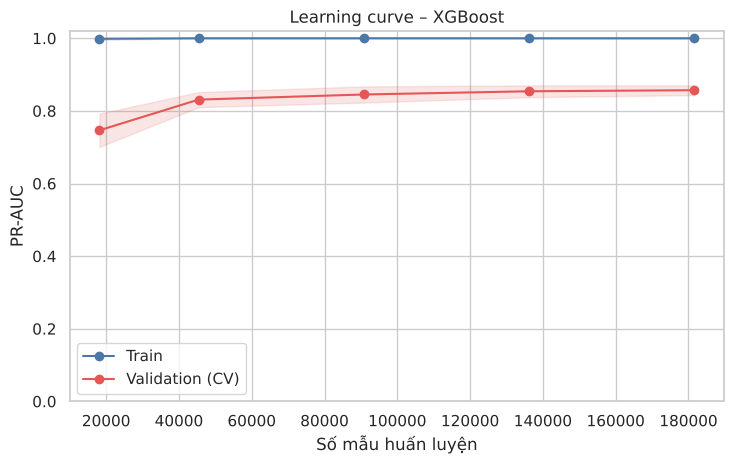

,Số mẫu train,PR-AUC train,PR-AUC validation,std validation
0,18158,0.9986,0.7465,0.0457
1,45396,1.0000,0.8311,0.0207
2,90792,1.0000,0.8452,0.0222
3,136188,1.0000,0.8540,0.0163
4,181584,1.0000,0.8569,0.0134


In [12]:
best_pipe_template = clone(searches[BEST_FAMILY].best_estimator_)
best_pipe_template.set_params(**({"model__n_jobs": 2} if hasattr(best_pipe_template.named_steps["model"], "n_jobs") else {}))

sizes, tr_scores, va_scores = learning_curve(
    best_pipe_template, X_train, y_train, cv=CV_FINAL, scoring="average_precision",
    train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0], n_jobs=1, shuffle=True, random_state=RANDOM_STATE)
lc = pd.DataFrame({"Số mẫu train": sizes, "PR-AUC train": tr_scores.mean(1), "PR-AUC validation": va_scores.mean(1),
                   "std validation": va_scores.std(1)})
lc.to_csv(TAB_DIR / "learning_curve.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(sizes, tr_scores.mean(1), "o-", color=C_NORMAL, label="Train")
ax.fill_between(sizes, tr_scores.mean(1) - tr_scores.std(1), tr_scores.mean(1) + tr_scores.std(1), alpha=0.15, color=C_NORMAL)
ax.plot(sizes, va_scores.mean(1), "o-", color=C_FRAUD, label="Validation (CV)")
ax.fill_between(sizes, va_scores.mean(1) - va_scores.std(1), va_scores.mean(1) + va_scores.std(1), alpha=0.15, color=C_FRAUD)
ax.set(xlabel="Số mẫu huấn luyện", ylabel="PR-AUC", title=f"Learning curve – {BEST_FAMILY}", ylim=(0, 1.02))
ax.legend()
plt.tight_layout()
save_fig("13_learning_curve")
plt.show()
lc

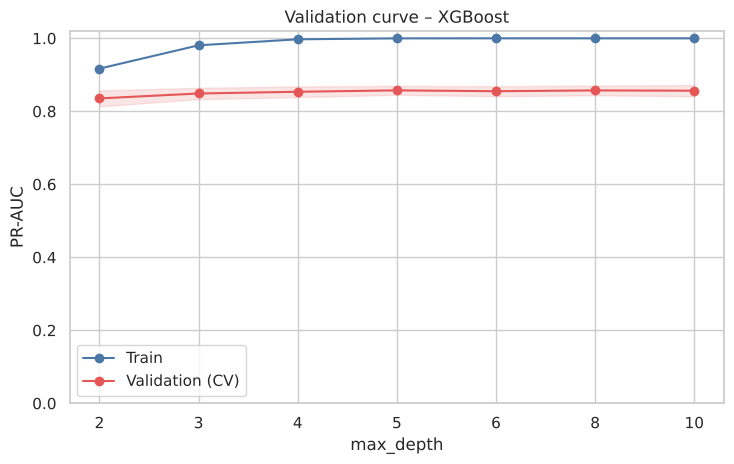

,model__max_depth,PR-AUC train,PR-AUC validation,std validation
0,2,0.9169,0.8354,0.0217
1,3,0.9808,0.8488,0.0156
2,4,0.9973,0.8535,0.0146
3,5,0.9999,0.8574,0.0123
4,6,1.0000,0.8551,0.0137
5,8,1.0000,0.8572,0.0134
6,10,1.0000,0.8564,0.0154


In [13]:
VALIDATION_PARAM = {
    "XGBoost": ("model__max_depth", [2, 3, 4, 5, 6, 8, 10]),
    "Random Forest": ("model__max_depth", [4, 6, 8, 12, 16, 24]),
    "Decision Tree": ("model__max_depth", [2, 3, 4, 6, 8, 12, 16]),
    "Logistic Regression": ("model__C", [0.001, 0.01, 0.1, 1, 10, 100]),
    "k-NN": ("model__n_neighbors", [1, 3, 5, 11, 21, 41, 81]),
}
param_name, param_range = VALIDATION_PARAM[BEST_FAMILY]
v_train, v_valid = validation_curve(
    best_pipe_template, X_train, y_train, param_name=param_name, param_range=param_range,
    cv=CV_FINAL, scoring="average_precision", n_jobs=1)
vc = pd.DataFrame({param_name: param_range, "PR-AUC train": v_train.mean(1), "PR-AUC validation": v_valid.mean(1),
                   "std validation": v_valid.std(1)})
vc.to_csv(TAB_DIR / "validation_curve.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4.8))
x = np.arange(len(param_range))
ax.plot(x, v_train.mean(1), "o-", color=C_NORMAL, label="Train")
ax.plot(x, v_valid.mean(1), "o-", color=C_FRAUD, label="Validation (CV)")
ax.fill_between(x, v_valid.mean(1) - v_valid.std(1), v_valid.mean(1) + v_valid.std(1), alpha=0.15, color=C_FRAUD)
ax.set_xticks(x, [str(v) for v in param_range])
ax.set(xlabel=param_name.split("__")[1], ylabel="PR-AUC", title=f"Validation curve – {BEST_FAMILY}", ylim=(0, 1.02))
ax.legend()
plt.tight_layout()
save_fig("14_validation_curve")
plt.show()
vc

**Nhận xét (mục 7).** * **Learning curve**: PR-AUC train luôn xấp xỉ 1,0 trong khi PR-AUC validation tăng từ 0,747 (18 nghìn mẫu) lên 0,857 (toàn bộ ~182 nghìn mẫu của các fold train). Khoảng cách lớn này là dấu hiệu **overfitting (phương sai cao)**: mô hình học thuộc tập train, nhưng không phải *underfitting*. Đường validation đã gần như phẳng ở cuối (0,854 lên 0,857 khi tăng thêm 45 nghìn mẫu), nên thêm dữ liệu cùng loại chỉ giúp rất ít; thêm *ca gian lận* mới hay đặc trưng mới có nhiều khả năng giúp hơn.
* **Validation curve theo `max_depth`**: PR-AUC validation tăng nhanh từ độ sâu 2 (0,835) đến 5 (0,857) rồi đi ngang (0,855 - 0,857 ở độ sâu 6 - 10), trong khi PR-AUC train tiếp tục tiến tới 1,0. Tức là sau độ sâu ~5, tăng độ phức tạp chỉ làm tăng khoảng cách train-validation mà không cải thiện khả năng tổng quát hóa. Độ sâu đã chọn ở bước tuning (8) nằm trên vùng phẳng này nên không gây hại đáng kể, tuy nhiên độ sâu 5 là lựa chọn đơn giản tương đương.

## 8. Chọn ngưỡng quyết định

Ngưỡng mặc định 0,5 hiếm khi hợp lý khi dữ liệu mất cân bằng (xác suất bị lệch bởi trọng số lớp hoặc lấy mẫu lại). Ngưỡng được chọn **chỉ từ dự đoán out-of-fold của tập train** (mục 6), với tiêu chí **cực đại hóa F2** (ưu tiên Recall đúng với mục tiêu đề tài). Tập test không tham gia.

Để minh họa sự đánh đổi, bảng dưới đây cũng cho các điểm vận hành khác: cực đại F1, và ngưỡng cho Precision cao nhất mà vẫn đạt Recall ≥ 0,85 / 0,90.

In [14]:
best_oof = oof_scores[BEST_FAMILY]
operating_points = {
    "Mặc định 0,5": 0.5,
    "Cực đại F1": choose_threshold(y_train, best_oof, "f1"),
    "Cực đại F2 (CHỌN)": choose_threshold(y_train, best_oof, "f2"),
    "Recall ≥ 0,85": choose_threshold(y_train, best_oof, "recall_floor", 0.85),
    "Recall ≥ 0,90": choose_threshold(y_train, best_oof, "recall_floor", 0.90),
}
op_rows = []
for name, thr in operating_points.items():
    m = compute_metrics(y_train, best_oof, thr)
    op_rows.append({"Điểm vận hành": name, "Ngưỡng": thr, "Recall": m["Recall"], "Precision": m["Precision"],
                    "F1": m["F1"], "F2": m["F2"], "TP": m["TP"], "FP": m["FP"], "FN": m["FN"]})
op_table = pd.DataFrame(op_rows)
op_table.to_csv(TAB_DIR / "operating_points_oof.csv", index=False)
THRESHOLD = operating_points["Cực đại F2 (CHỌN)"]
print(f"Ngưỡng được chọn (cực đại F2 trên OOF của train): {THRESHOLD:.4f}")
op_table

Ngưỡng được chọn (cực đại F2 trên OOF của train): 0.4671


,Điểm vận hành,Ngưỡng,Recall,Precision,F1,F2,TP,FP,FN
0,"Mặc định 0,5",0.5000,0.8280,0.9179,0.8707,0.8446,313,28,65
1,Cực đại F1,0.4671,0.8307,0.9181,0.8722,0.8468,314,28,64
2,Cực đại F2 (CHỌN),0.4671,0.8307,0.9181,0.8722,0.8468,314,28,64
3,"Recall ≥ 0,85",0.0571,0.8519,0.7594,0.8030,0.8316,322,102,56
4,"Recall ≥ 0,90",0.0020,0.9021,0.1595,0.2711,0.4671,341,1797,37


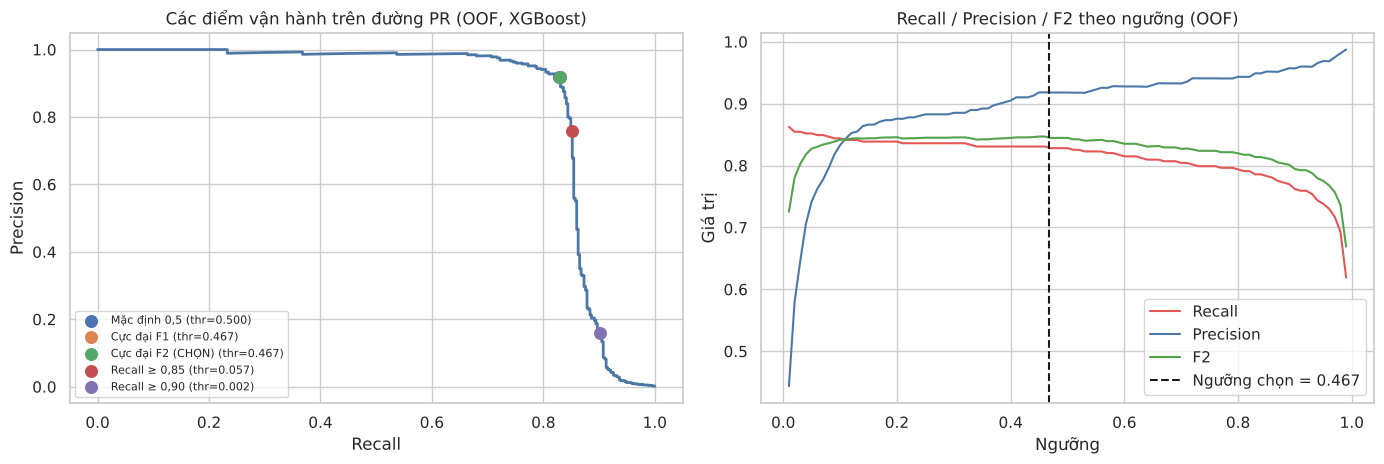

In [15]:
p, r, t = precision_recall_curve(y_train, best_oof)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(r, p, color=C_NORMAL, lw=2)
for name, thr in operating_points.items():
    m = compute_metrics(y_train, best_oof, thr)
    axes[0].scatter(m["Recall"], m["Precision"], s=70, zorder=3, label=f"{name} (thr={thr:.3f})")
axes[0].set(xlabel="Recall", ylabel="Precision", title=f"Các điểm vận hành trên đường PR (OOF, {BEST_FAMILY})")
axes[0].legend(fontsize=8)
grid = np.linspace(0.01, 0.99, 99)
curves = pd.DataFrame([compute_metrics(y_train, best_oof, g) for g in grid])
for col, c in [("Recall", C_FRAUD), ("Precision", C_NORMAL), ("F2", "#54A24B")]:
    axes[1].plot(grid, curves[col], label=col, color=c)
axes[1].axvline(THRESHOLD, color="k", ls="--", label=f"Ngưỡng chọn = {THRESHOLD:.3f}")
axes[1].set(xlabel="Ngưỡng", ylabel="Giá trị", title="Recall / Precision / F2 theo ngưỡng (OOF)")
axes[1].legend()
plt.tight_layout()
save_fig("15_threshold_selection")
plt.show()

## 9. Đánh giá khách quan trên tập test độc lập

**Đây là lần đầu tiên tập test được sử dụng.** Mô hình, siêu tham số và ngưỡng đều đã cố định từ trước. Các pipeline tốt nhất của mục 5 đã được `refit` trên toàn bộ tập train. Mỗi mô hình dùng ngưỡng F2 riêng, tính từ điểm out-of-fold của chính nó. Việc chọn mô hình tốt nhất đã hoàn tất ở mục 6 (theo CV), nên bảng test dưới đây chỉ để báo cáo, không dùng để chọn lại.

In [16]:
final_models = {f: searches[f].best_estimator_ for f in FAMILIES}      # đã fit trên toàn bộ train
thresholds = {f: choose_threshold(y_train, oof_scores[f], "f2") for f in FAMILIES}

baseline_fit = make_baseline().fit(X_train, y_train)
test_scores = {"Baseline (Dummy)": baseline_fit.predict_proba(X_test)[:, 1]}
for f in FAMILIES:
    test_scores[f] = final_models[f].predict_proba(X_test)[:, 1]

rows = []
for name, score in test_scores.items():
    m05 = compute_metrics(y_test, score, 0.5)
    thr = thresholds.get(name, 0.5)
    mt = compute_metrics(y_test, score, thr)
    rows.append({"Mô hình": name, "PR-AUC": m05["PR-AUC"], "ROC-AUC": m05["ROC-AUC"],
                 "Recall @0.5": m05["Recall"], "Precision @0.5": m05["Precision"], "F2 @0.5": m05["F2"],
                 "Ngưỡng": thr, "Recall @thr": mt["Recall"], "Precision @thr": mt["Precision"],
                 "F1 @thr": mt["F1"], "F2 @thr": mt["F2"], "MCC @thr": mt["MCC"],
                 "TP": mt["TP"], "FP": mt["FP"], "FN": mt["FN"]})
test_table = pd.DataFrame(rows).set_index("Mô hình")
test_table.to_csv(TAB_DIR / "test_comparison_all_models.csv")
test_table

,PR-AUC,ROC-AUC,Recall @0.5,Precision @0.5,F2 @0.5,Ngưỡng,Recall @thr,Precision @thr,F1 @thr,F2 @thr,MCC @thr,TP,FP,FN
Mô hình,,,,,,,,,,,,,,
Baseline (Dummy),0.0017,0.5000,0.0000,0.0000,0.0000,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0,0,95
Logistic Regression,0.7601,0.9645,0.8105,0.6875,0.7825,0.6256,0.7789,0.7872,0.7831,0.7806,0.7827,74,20,21
k-NN,0.7244,0.9267,0.7368,0.8140,0.7511,0.1860,0.7789,0.7115,0.7437,0.7645,0.7440,74,30,21
Decision Tree,0.6859,0.9355,0.8211,0.1632,0.4545,0.9728,0.7158,0.8947,0.7953,0.7456,0.8000,68,8,27
Random Forest,0.8194,0.9737,0.7789,0.8132,0.7856,0.6312,0.7579,0.8780,0.8136,0.7792,0.8155,72,10,23
XGBoost,0.8197,0.9751,0.7684,0.9605,0.8004,0.4671,0.7684,0.9605,0.8538,0.8004,0.8589,73,3,22


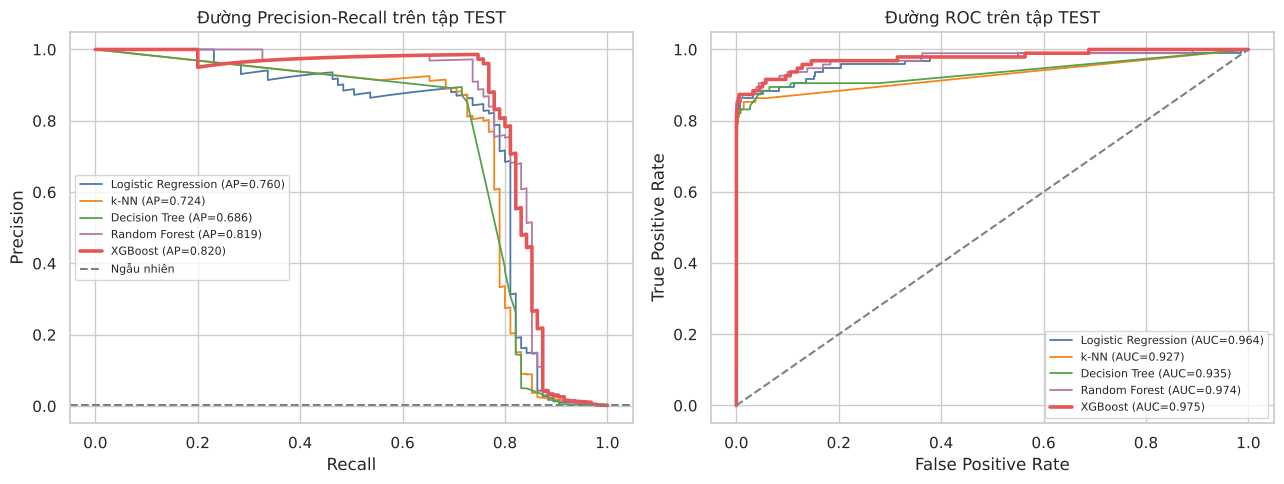

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, score in test_scores.items():
    if name.startswith("Baseline"):
        continue
    p, r, _ = precision_recall_curve(y_test, score)
    fpr, tpr, _ = roc_curve(y_test, score)
    lw = 2.6 if name == BEST_FAMILY else 1.3
    axes[0].plot(r, p, lw=lw, color=FAMILY_COLORS[name], label=f"{name} (AP={average_precision_score(y_test, score):.3f})")
    axes[1].plot(fpr, tpr, lw=lw, color=FAMILY_COLORS[name], label=f"{name} (AUC={roc_auc_score(y_test, score):.3f})")
axes[0].axhline(y_test.mean(), color="gray", ls="--", label="Ngẫu nhiên")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Đường Precision-Recall trên tập TEST")
axes[1].plot([0, 1], [0, 1], color="gray", ls="--")
axes[1].set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="Đường ROC trên tập TEST")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
save_fig("16_test_pr_roc_curves")
plt.show()

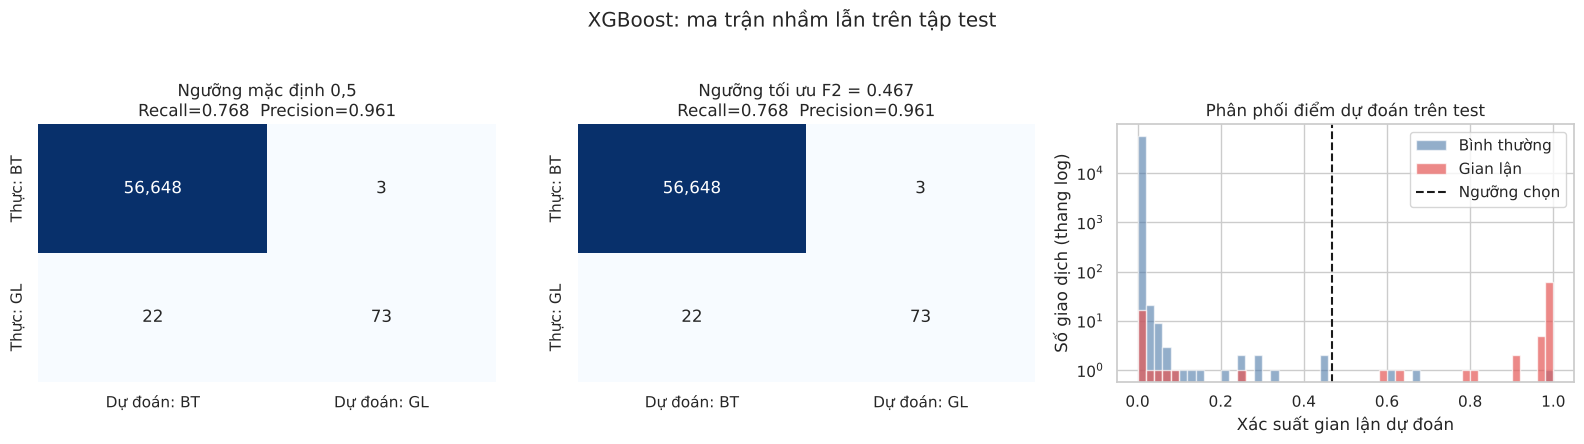

,Threshold,PR-AUC,ROC-AUC,Recall,Precision,F1,F2,MCC,TP,FP,FN,TN
"Ngưỡng 0,5",0.5000,0.8197,0.9751,0.7684,0.9605,0.8538,0.8004,0.8589,73,3,22,56648
Ngưỡng tối ưu F2,0.4671,0.8197,0.9751,0.7684,0.9605,0.8538,0.8004,0.8589,73,3,22,56648


In [18]:
best_score = test_scores[BEST_FAMILY]
m_default = compute_metrics(y_test, best_score, 0.5)
m_tuned = compute_metrics(y_test, best_score, THRESHOLD)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, m, title in [(axes[0], m_default, "Ngưỡng mặc định 0,5"),
                     (axes[1], m_tuned, f"Ngưỡng tối ưu F2 = {THRESHOLD:.3f}")]:
    cm = np.array([[m["TN"], m["FP"]], [m["FN"], m["TP"]]])
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Dự đoán: BT", "Dự đoán: GL"], yticklabels=["Thực: BT", "Thực: GL"])
    ax.set_title(f"{title}\nRecall={m['Recall']:.3f}  Precision={m['Precision']:.3f}")
axes[2].hist(best_score[y_test.to_numpy() == 0], bins=50, alpha=0.6, color=C_NORMAL, label="Bình thường", log=True)
axes[2].hist(best_score[y_test.to_numpy() == 1], bins=50, alpha=0.7, color=C_FRAUD, label="Gian lận", log=True)
axes[2].axvline(THRESHOLD, color="k", ls="--", label="Ngưỡng chọn")
axes[2].set(xlabel="Xác suất gian lận dự đoán", ylabel="Số giao dịch (thang log)", title="Phân phối điểm dự đoán trên test")
axes[2].legend()
plt.suptitle(f"{BEST_FAMILY}: ma trận nhầm lẫn trên tập test", y=1.03)
plt.tight_layout()
save_fig("17_confusion_matrices_test")
plt.show()

pd.DataFrame([m_default, m_tuned], index=["Ngưỡng 0,5", "Ngưỡng tối ưu F2"])[
    ["Threshold", "PR-AUC", "ROC-AUC", "Recall", "Precision", "F1", "F2", "MCC", "TP", "FP", "FN", "TN"]]

In [19]:
# Khoảng tin cậy bootstrap 95% (tập test chỉ có ~95 ca gian lận nên các chỉ số dao động mạnh)
ci = bootstrap_ci(y_test, best_score, THRESHOLD, n_boot=1000, seed=RANDOM_STATE)
point = {"PR-AUC": m_tuned["PR-AUC"], "Recall": m_tuned["Recall"], "Precision": m_tuned["Precision"], "F2": m_tuned["F2"]}
ci.insert(1, "Ước lượng điểm", ci["Chỉ số"].map(point))
ci.to_csv(TAB_DIR / "test_bootstrap_ci.csv", index=False)
ci

,Chỉ số,Ước lượng điểm,Cận dưới 95%,Cận trên 95%
0,PR-AUC,0.8197,0.7393,0.8900
1,Recall,0.7684,0.6842,0.8526
2,Precision,0.9605,0.9155,1.0000
3,F2,0.8004,0.7238,0.8728


**Nhận xét (mục 9).** * Đây là **lần duy nhất** tập test được dùng. Ngưỡng 0,4671 được chọn từ dự đoán OOF của tập train (không nhìn test).
* **XGBoost trên test: PR-AUC 0,820 [KTC 95% 0,739 - 0,890], Recall 0,768 [0,684 - 0,853], Precision 0,961 [0,916 - 1,000], F2 0,800**; bắt được 73/95 ca gian lận với chỉ 3 cảnh báo nhầm trên 56.651 giao dịch bình thường.
* Con số test thấp hơn CV (PR-AUC 0,857, Recall 0,831): đây là hiện tượng bình thường vì (i) tập test chỉ có **95 ca gian lận**, mỗi ca thay đổi Recall ~1 điểm phần trăm, nên khoảng tin cậy rất rộng (±0,08); (ii) các giá trị CV nằm trong khoảng tin cậy của test. Không nên diễn giải chênh lệch này như dấu hiệu rò rỉ hay mô hình hỏng.
* **XGBoost và Random Forest gần như bằng nhau trên test về PR-AUC** (0,8197 so với 0,8194); XGBoost nổi trội ở Precision (0,96 so với 0,88) và số cảnh báo nhầm (3 so với 10).
* **Lưu ý về mục tiêu Recall**: ngưỡng cực đại F2 cho Recall 0,77 với Precision rất cao. Nếu nghiệp vụ ưu tiên bắt nhiều hơn, có thể hạ ngưỡng; theo OOF của train, ngưỡng 0,057 cho Recall 0,85 với Precision 0,76, còn Recall 0,90 phải trả giá bằng Precision 0,16 (1.797 cảnh báo nhầm trên 378 ca gian lận). Việc chọn điểm vận hành là quyết định kinh doanh, bảng `operating_points_oof.csv` cung cấp các lựa chọn.

## 10. Phân tích lỗi (Error Analysis)

Phân tích giao dịch gian lận bị bỏ sót (**False Negative**) và cảnh báo nhầm (**False Positive**) của mô hình tốt nhất trên tập test, tại ngưỡng đã chọn. Đây là phân tích *mô tả* để hiểu mô hình, không dùng để chỉnh sửa mô hình (nếu chỉnh theo test sẽ gây rò rỉ).

In [20]:
y_true = y_test.to_numpy()
pred = (best_score >= THRESHOLD).astype(int)
outcome = np.select([(y_true == 1) & (pred == 1), (y_true == 1) & (pred == 0),
                     (y_true == 0) & (pred == 1)], ["TP", "FN", "FP"], default="TN")
err = X_test.copy()
err["Class"], err["score"], err["outcome"] = y_true, best_score, outcome
err["Hour"] = (err.Time % 86400) / 3600
print(err.outcome.value_counts().to_string())

profile_cols = ["Amount", "Hour", "V14", "V17", "V12", "V10", "score"]
prof = err[err.outcome.isin(["TP", "FN", "FP"])].groupby("outcome")[profile_cols].median().T
prof["TN (tham chiếu)"] = err[err.outcome == "TN"][profile_cols].median()
prof.to_csv(TAB_DIR / "error_analysis_profile.csv")
print("\nTrung vị của từng nhóm kết quả:")
prof

outcome
TN    56648
TP       73
FN       22
FP        3

Trung vị của từng nhóm kết quả:


outcome,FN,FP,TP,TN (tham chiếu)
Amount,2.9900,109.9000,33.5900,21.6000
Hour,14.9892,21.0294,11.4736,14.9969
V14,-0.6817,-6.7959,-7.1322,0.0572
V17,0.9190,-7.1738,-5.3046,-0.0663
V12,-0.3116,-7.1045,-6.1514,0.1446
V10,-0.2169,-5.6220,-5.1531,-0.0905
score,0.0004,0.6643,0.9965,0.0000


Các giao dịch gian lận bị BỎ SÓT (FN), sắp xếp theo xác suất mô hình gán:


,Time,Amount,V14,V17,V12,V10,score
87035,"61,646.0000",19.0400,-3.4317,-3.9015,-2.3170,0.1696,0.2412
228883,"146,026.0000",2.2200,-4.9426,3.7021,-0.7411,-0.6285,0.0822
10442,"17,187.0000",3.7900,-0.3303,2.2990,-2.5476,-0.5925,0.0646
239334,"150,494.0000",1.0000,-4.2525,2.9345,-1.4632,-0.3739,0.0527
14285,"25,426.0000",3.7600,-2.2386,1.7765,-0.4912,-0.3699,0.0310
231118,"146,998.0000",8.0000,-3.6888,2.3470,-0.3388,-0.8872,0.0143
194676,"131,024.0000",723.2100,-2.3066,1.1657,-0.0544,0.0857,0.0104
68058,"52,934.0000",0.7600,-2.3767,1.5915,-0.1588,-0.2837,0.0086
145246,"87,202.0000",451.2700,-0.4292,1.6800,-0.2844,-0.1340,0.0039
153692,"101,051.0000",0.9200,3.4424,1.4182,-1.4717,1.7859,0.0030


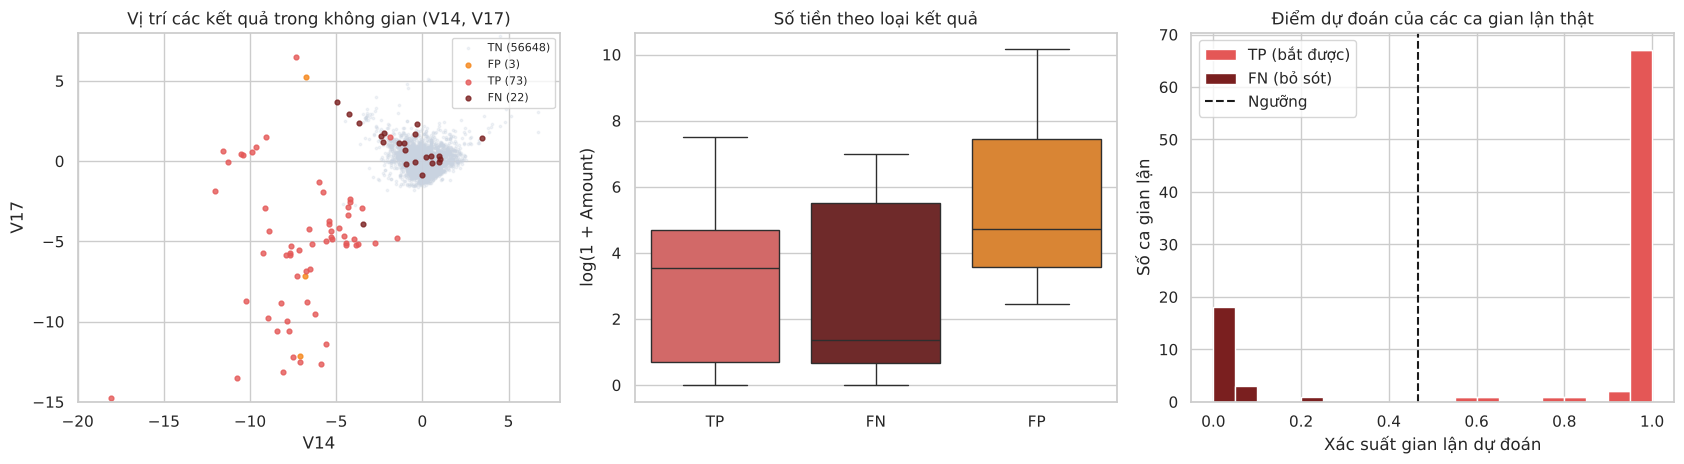

In [21]:
fn = err[err.outcome == "FN"].sort_values("score", ascending=False)
print("Các giao dịch gian lận bị BỎ SÓT (FN), sắp xếp theo xác suất mô hình gán:")
display(fn[["Time", "Amount", "V14", "V17", "V12", "V10", "score"]].round(4))
fn.to_csv(TAB_DIR / "false_negatives_test.csv")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
palette = {"TN": "#C9D3E0", "FP": "#F58518", "FN": "#7A1F1F", "TP": C_FRAUD}
order = ["TN", "FP", "TP", "FN"]
sub = err.sample(frac=1, random_state=RANDOM_STATE)
for oc in order:
    d = sub[sub.outcome == oc]
    if oc == "TN":
        d = d.sample(min(len(d), 4000), random_state=RANDOM_STATE)
    axes[0].scatter(d.V14, d.V17, s=12 if oc != "TN" else 3, alpha=0.8 if oc != "TN" else 0.25,
                    color=palette[oc], label=f"{oc} ({(err.outcome == oc).sum()})")
axes[0].set(xlabel="V14", ylabel="V17", xlim=(-20, 8), ylim=(-15, 8), title="Vị trí các kết quả trong không gian (V14, V17)")
axes[0].legend(fontsize=8)

amt = err[err.outcome.isin(["TP", "FN", "FP"])]
sns.boxplot(data=amt, x="outcome", y=np.log1p(amt.Amount), order=["TP", "FN", "FP"],
            hue="outcome", palette=palette, legend=False, ax=axes[1])
axes[1].set(ylabel="log(1 + Amount)", xlabel="", title="Số tiền theo loại kết quả")

fraud_only = err[err.Class == 1]
axes[2].hist([fraud_only.loc[fraud_only.outcome == "TP", "score"], fraud_only.loc[fraud_only.outcome == "FN", "score"]],
             bins=np.linspace(0, 1, 21), color=[C_FRAUD, palette["FN"]], label=["TP (bắt được)", "FN (bỏ sót)"], stacked=True)
axes[2].axvline(THRESHOLD, color="k", ls="--", label="Ngưỡng")
axes[2].set(xlabel="Xác suất gian lận dự đoán", ylabel="Số ca gian lận", title="Điểm dự đoán của các ca gian lận thật")
axes[2].legend()
plt.tight_layout()
save_fig("18_error_analysis")
plt.show()

In [22]:
# Góc nhìn nghiệp vụ: tính theo số tiền giao dịch.
# Giả định MINH HỌA (không có trong dữ liệu): mỗi cảnh báo cần một lần xét duyệt thủ công tốn REVIEW_COST.
REVIEW_COST = 5.0
fraud_amt = err.loc[err.Class == 1, "Amount"]
caught_amt = err.loc[err.outcome == "TP", "Amount"].sum()
missed_amt = err.loc[err.outcome == "FN", "Amount"].sum()
n_alerts = int((pred == 1).sum())
n_fp = int((err.outcome == "FP").sum())

business = pd.DataFrame({
    "Chỉ tiêu": ["Tổng số tiền gian lận trong tập test", "Số tiền gian lận chặn được (TP)",
                 "Số tiền gian lận bị bỏ lọt (FN)", "Tỷ lệ số tiền gian lận chặn được",
                 "Tỷ lệ ca gian lận chặn được (Recall)", "Số cảnh báo phát ra", "Trong đó cảnh báo nhầm (FP)",
                 f"Chi phí xét duyệt giả định ({REVIEW_COST:.0f}/cảnh báo)",
                 "Số tiền tiết kiệm ròng = chặn được - chi phí xét duyệt"],
    "Giá trị": [fraud_amt.sum(), caught_amt, missed_amt, caught_amt / fraud_amt.sum(),
                m_tuned["Recall"], n_alerts, n_fp, n_alerts * REVIEW_COST, caught_amt - n_alerts * REVIEW_COST],
})
business.to_csv(TAB_DIR / "business_impact_test.csv", index=False)
business

,Chỉ tiêu,Giá trị
0,Tổng số tiền gian lận trong tập test,"14,766.3100"
1,Số tiền gian lận chặn được (TP),"10,954.7100"
2,Số tiền gian lận bị bỏ lọt (FN),"3,811.6000"
3,Tỷ lệ số tiền gian lận chặn được,0.7419
4,Tỷ lệ ca gian lận chặn được (Recall),0.7684
5,Số cảnh báo phát ra,76.0000
6,Trong đó cảnh báo nhầm (FP),3.0000
7,Chi phí xét duyệt giả định (5/cảnh báo),380.0000
8,Số tiền tiết kiệm ròng = chặn được - chi phí x...,"10,574.7100"


**Nhận xét (mục 10).** * **22 ca gian lận bị bỏ sót (FN)**: trung vị xác suất mô hình gán chỉ 0,0004; **15/22 ca có xác suất dưới 0,01** và chỉ 1 ca vượt 0,1. Các ca này trông *giống hệt giao dịch bình thường* trong không gian đặc trưng (trung vị V14 = -0,68, V17 = 0,92, V12 = -0,31, trong khi các ca bắt được có V14 ≈ -7,1, V17 ≈ -5,3, V12 ≈ -6,2). Vì vậy việc hạ ngưỡng không cứu được chúng (phải hạ rất thấp, kèm hàng nghìn cảnh báo nhầm).
* Phần lớn FN là giao dịch **số tiền nhỏ** (14/22 ca dưới 10; trung vị 2,99) - phù hợp với kiểu kiểm tra thẻ bằng giao dịch nhỏ, vốn khó phân biệt với giao dịch hợp lệ. Một số ít có số tiền lớn (tối đa 1.097).
* **3 cảnh báo nhầm (FP)** có hồ sơ giống gian lận (V14, V17, V12, V10 rất âm, trung vị xác suất 0,66) và số tiền lớn hơn (trung vị 110); tức là chúng là những giao dịch bình thường *thực sự trông giống gian lận*, khó tránh khỏi.
* **Tác động nghiệp vụ (minh họa, chi phí xét duyệt 5/cảnh báo là *giả định*)**: mô hình chặn được 74,2% giá trị tiền gian lận (10.955 trên 14.766), bỏ lọt 3.812; chi phí xét duyệt 380; tiết kiệm ròng ~10.575. Tỷ lệ tiền chặn được (74,2%) thấp hơn nhẹ Recall theo số ca (76,8%) vì mô hình bỏ sót một số ca giá trị lớn.
* Hướng cải thiện: (i) thêm đặc trưng hành vi theo khách hàng/thẻ (không có trong dữ liệu ẩn danh này); (ii) mô hình riêng cho giao dịch nhỏ; (iii) thu thập thêm ca gian lận.

## 11. Vì sao mô hình tốt nhất vượt trội?

Để biết chênh lệch giữa mô hình tốt nhất và các mô hình khác có phải do may rủi của tập test nhỏ hay không, dùng **bootstrap ghép cặp**: lấy mẫu lại cùng một tập chỉ số test cho cả hai mô hình, tính hiệu PR-AUC, lặp 500 lần.

In [23]:
rng = np.random.default_rng(RANDOM_STATE)
pos, neg = np.where(y_true == 1)[0], np.where(y_true == 0)[0]
boot_idx = [np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(500)]
rows = []
for f in FAMILIES:
    if f == BEST_FAMILY:
        continue
    diffs = np.array([average_precision_score(y_true[i], test_scores[BEST_FAMILY][i]) -
                      average_precision_score(y_true[i], test_scores[f][i]) for i in boot_idx])
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    rows.append({"So với": f, "Chênh lệch PR-AUC (tốt nhất - mô hình khác)": diffs.mean(),
                 "Cận dưới 95%": lo, "Cận trên 95%": hi, "Tỷ lệ bootstrap thắng": (diffs > 0).mean()})
paired_test = pd.DataFrame(rows)
paired_test.to_csv(TAB_DIR / "paired_bootstrap_vs_best.csv", index=False)
paired_test

,So với,Chênh lệch PR-AUC (tốt nhất - mô hình khác),Cận dưới 95%,Cận trên 95%,Tỷ lệ bootstrap thắng
0,Logistic Regression,0.0587,0.0179,0.1068,1.0000
1,k-NN,0.0952,0.0412,0.1512,1.0000
2,Decision Tree,0.1340,0.0767,0.2039,1.0000
3,Random Forest,0.0003,-0.0159,0.0146,0.5320


**Nhận xét (mục 11).** * Bootstrap ghép cặp (1.000 lần) cho thấy **XGBoost vượt Logistic Regression (+0,059), k-NN (+0,095) và Decision Tree (+0,134) một cách có ý nghĩa**: khoảng tin cậy 95% của hiệu PR-AUC đều nằm hoàn toàn trên 0 và XGBoost thắng ở 100% lần lấy mẫu.
* **Với Random Forest thì không phân biệt được**: hiệu PR-AUC chỉ +0,0003, KTC [-0,016; +0,015], thắng 53% số lần. Trung thực mà nói, dữ liệu test (95 ca gian lận) không đủ để kết luận XGBoost tốt hơn Random Forest về PR-AUC. XGBoost được chọn dựa trên CV (thắng 4/5 fold), tốc độ huấn luyện (~35 lần nhanh hơn), mô hình nhỏ gọn (0,24 MB) và Precision cao hơn tại ngưỡng đã chọn.
* **Lý do mô hình cây tăng cường vượt trội** (giải thích, không phải kết luận được kiểm chứng riêng): dữ liệu gồm các thành phần PCA có quan hệ phi tuyến và tương tác với nhau; boosting học được các ranh giới phi tuyến này, đồng thời regularization (`min_child_weight`, `gamma`, `subsample`, `colsample_bytree`) và `scale_pos_weight` giúp kiểm soát phương sai và mất cân bằng. Logistic Regression chỉ có biên tuyến tính, k-NN chịu lời nguyền số chiều, và một cây đơn lẻ có phương sai cao.

## 12. Mức độ quan trọng đặc trưng

Dùng hai góc nhìn bổ sung trên mô hình tốt nhất:
1. **Permutation importance** trên các cột *gốc* (đầu vào của pipeline): xáo trộn một cột và đo PR-AUC giảm bao nhiêu. Vì xáo cột gốc làm thay đổi đồng thời các đặc trưng dẫn xuất từ nó (ví dụ `V14` cũng làm đổi các tương tác chứa `V14`), kết quả phản ánh **đóng góp tổng thể** của từng biến gốc.
2. **SHAP** (nếu mô hình là cây) trên các đặc trưng *sau* kỹ nghệ/tiền xử lý, để thấy riêng đóng góp của đặc trưng tự tạo và chiều tác động.

Cả hai chỉ để giải thích mô hình đã chốt, không dùng để chọn lại đặc trưng.

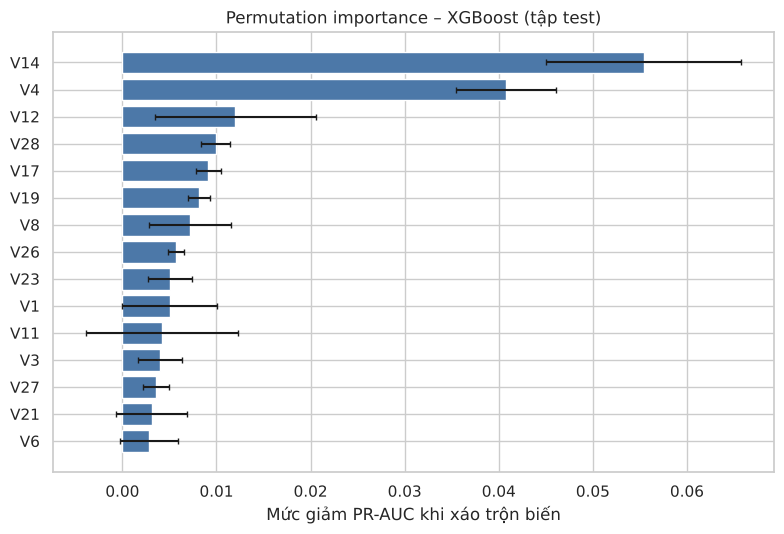

,Biến gốc,Giảm PR-AUC (TB),std
0,V14,0.0554,0.0104
1,V4,0.0407,0.0053
2,V12,0.0120,0.0086
3,V28,0.0099,0.0016
4,V17,0.0091,0.0013
5,V19,0.0082,0.0012
6,V8,0.0072,0.0043
7,V26,0.0057,0.0009
8,V23,0.0051,0.0023
9,V1,0.0050,0.0050


In [24]:
best_pipeline = final_models[BEST_FAMILY]
perm = permutation_importance(best_pipeline, X_test, y_test, scoring="average_precision",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=2)
perm_df = (pd.DataFrame({"Biến gốc": X_test.columns, "Giảm PR-AUC (TB)": perm.importances_mean,
                         "std": perm.importances_std})
           .sort_values("Giảm PR-AUC (TB)", ascending=False).reset_index(drop=True))
perm_df.to_csv(TAB_DIR / "permutation_importance.csv", index=False)

top = perm_df.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top["Biến gốc"], top["Giảm PR-AUC (TB)"], xerr=top["std"], color=C_NORMAL, capsize=2)
ax.set(xlabel="Mức giảm PR-AUC khi xáo trộn biến", title=f"Permutation importance – {BEST_FAMILY} (tập test)")
plt.tight_layout()
save_fig("19_permutation_importance")
plt.show()
perm_df.head(10)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


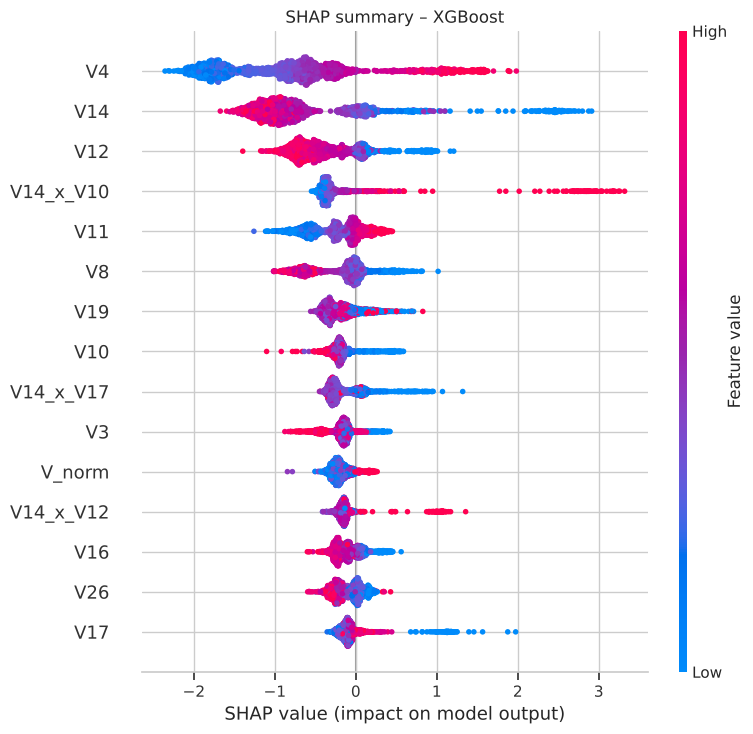

,Đặc trưng,Mean |SHAP|
0,V4,1.0419
1,V14,0.8677
2,V12,0.4797
3,V14_x_V10,0.4312
4,V11,0.2940
5,V8,0.2845
6,V19,0.2434
7,V10,0.2298
8,V14_x_V17,0.2262
9,V3,0.2082


In [25]:
import shap

fe_step, prep_step = best_pipeline.named_steps["fe"], best_pipeline.named_steps["prep"]
feature_names = list(best_pipeline.named_steps["prep"].get_feature_names_out())
model = best_pipeline.named_steps["model"]
is_tree = BEST_FAMILY in ("XGBoost", "Random Forest", "Decision Tree")

if is_tree:
    # Mẫu để tính SHAP: toàn bộ ca gian lận của test + 2000 ca bình thường ngẫu nhiên
    rs = np.random.default_rng(RANDOM_STATE)
    idx_neg = rs.choice(np.where(y_true == 0)[0], 2000, replace=False)
    idx = np.concatenate([np.where(y_true == 1)[0], idx_neg])
    Xs = pd.DataFrame(prep_step.transform(fe_step.transform(X_test.iloc[idx])), columns=feature_names)
    explainer = shap.TreeExplainer(model)
    sv = explainer.shap_values(Xs)
    if isinstance(sv, list):          # sklearn trả về list theo lớp
        sv = sv[1]
    elif getattr(sv, "ndim", 2) == 3:
        sv = sv[:, :, 1]
    plt.figure()
    shap.summary_plot(sv, Xs, max_display=15, show=False)
    plt.title(f"SHAP summary – {BEST_FAMILY}")
    plt.tight_layout()
    save_fig("20_shap_summary")
    plt.show()
    shap_imp = (pd.DataFrame({"Đặc trưng": feature_names, "Mean |SHAP|": np.abs(sv).mean(0)})
                .sort_values("Mean |SHAP|", ascending=False).reset_index(drop=True))
    shap_imp.to_csv(TAB_DIR / "shap_importance.csv", index=False)
    display(shap_imp.head(12))
else:
    print("Mô hình tốt nhất không phải mô hình cây; bỏ qua SHAP cho cây.")

**Nhận xét (mục 12).** * **Permutation importance (cột gốc)**: V14 là quan trọng nhất (PR-AUC giảm 0,055 khi xáo trộn), tiếp theo là V4 (0,041), sau đó mới tới V12, V28, V17. Các cột còn lại đóng góp rất nhỏ, và **Amount, Time có mức giảm xấp xỉ 0 hoặc hơi âm trong khoảng nhiễu** (độ lệch chuẩn lớn hơn giá trị trung bình) - tức là số tiền và thời điểm riêng lẻ gần như không giúp ích khi đã có các thành phần V.
* **SHAP** xác nhận V4, V14, V12 là ba biến chi phối. Đáng chú ý, **đặc trưng kỹ nghệ `V14_x_V10` đứng thứ 4** và `V14_x_V17`, `V_norm`, `V14_x_V12` nằm trong top 12, cho thấy mô hình có dùng các đặc trưng tương tác; nhóm thời điểm (`Period_*`), `Amount_small` gần như không đóng góp.
* Hai phương pháp không hoàn toàn trùng nhau (SHAP xếp V4 cao nhất còn permutation xếp V14 cao nhất; V10 có permutation âm nhưng SHAP trung bình). Điều này là bình thường: permutation chịu ảnh hưởng của sự tương quan giữa các đặc trưng (V10 trùng thông tin với V14_x_V10 nên xáo trộn riêng V10 không làm giảm), còn SHAP đo mức đóng góp vào đầu ra. Vì V1-V28 là thành phần PCA ẩn danh nên ta không giải thích được ý nghĩa nghiệp vụ của từng biến.

## 13. Kiểm tra độ bền theo thời gian

Chia ngẫu nhiên có thể lạc quan vì giao dịch cùng thời điểm có thể giống nhau. Kiểm tra bổ sung **chỉ dùng tập train**: huấn luyện trên 80% giao dịch *cũ nhất* (theo `Time`), kiểm tra trên 20% *mới nhất*, với đúng cấu hình và ngưỡng đã chọn. Tập test vẫn không bị động tới.

In [26]:
order_idx = np.argsort(X_train["Time"].to_numpy())
cut = int(0.8 * len(order_idx))
tr_i, va_i = order_idx[:cut], order_idx[cut:]
temporal_pipe = clone(searches[BEST_FAMILY].best_estimator_).fit(X_train.iloc[tr_i], y_train.iloc[tr_i])
temporal_score = temporal_pipe.predict_proba(X_train.iloc[va_i])[:, 1]
y_va = y_train.iloc[va_i]
temporal = compute_metrics(y_va, temporal_score, THRESHOLD)
rand_split = compute_metrics(y_train, best_oof, THRESHOLD)
temporal_table = pd.DataFrame([
    {"Cách đánh giá": "Chia ngẫu nhiên (OOF 5-fold, train)", **{k: rand_split[k] for k in ["PR-AUC", "Recall", "Precision", "F2"]}},
    {"Cách đánh giá": f"Chia theo thời gian (80% cũ -> 20% mới; {int(y_va.sum())} ca gian lận)", **{k: temporal[k] for k in ["PR-AUC", "Recall", "Precision", "F2"]}},
])
temporal_table.to_csv(TAB_DIR / "temporal_validation.csv", index=False)
temporal_table

,Cách đánh giá,PR-AUC,Recall,Precision,F2
0,"Chia ngẫu nhiên (OOF 5-fold, train)",0.8557,0.8307,0.9181,0.8468
1,Chia theo thời gian (80% cũ -> 20% mới; 64 ca ...,0.8232,0.7812,0.9091,0.8039


**Nhận xét (mục 13).** * Khi huấn luyện trên 80% giao dịch cũ và kiểm tra trên 20% mới nhất (chỉ trong tập train; 64 ca gian lận ở phần kiểm tra), PR-AUC là 0,823 so với 0,856 khi chia ngẫu nhiên; Recall 0,781 so với 0,831; Precision vẫn cao (0,909).
* Mô hình **suy giảm nhẹ** khi phải dự đoán tương lai, đúng với trực giác rằng chia ngẫu nhiên hơi lạc quan. Tuy nhiên với chỉ 64 ca gian lận thì độ chênh này nằm trong khoảng nhiễu, ta nên coi đây là dấu hiệu cần theo dõi thay vì kết luận chắc chắn. Khi triển khai thực tế cần **huấn luyện lại định kỳ** và giám sát trượt dữ liệu (data drift).
* Dữ liệu chỉ bao phủ khoảng 2 ngày nên không đánh giá được tính mùa vụ dài hạn.

## 14. Đóng gói mô hình và kiểm thử hàm dự đoán

File `models/best_model.joblib` chứa một dictionary gồm: **pipeline hoàn chỉnh** (từ cột thô đến xác suất), **ngưỡng quyết định**, và siêu dữ liệu (tên mô hình, phiên bản thư viện, số liệu test). Pipeline đã fit trên toàn bộ tập train.

In [27]:
import datetime

bundle = {
    "pipeline": best_pipeline,
    "threshold": float(THRESHOLD),
    "threshold_objective": "Cực đại F2 trên dự đoán out-of-fold của tập train",
    "alt_thresholds": {k: float(v) for k, v in operating_points.items()},
    "model_name": BEST_FAMILY,
    "best_params": {k: (v.item() if isinstance(v, np.generic) else v) for k, v in searches[BEST_FAMILY].best_params_.items()},
    "input_columns": RAW_FEATURES,
    "positive_label": 1,
    "test_metrics": {k: (float(v) if not isinstance(v, (int, np.integer)) else int(v)) for k, v in m_tuned.items()},
    "library_versions": {"scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__,
                         "joblib": joblib.__version__},
    "created": datetime.date.today().isoformat(),
}
joblib.dump(bundle, MODEL_DIR / "best_model.joblib", compress=3)
size_mb = (MODEL_DIR / "best_model.joblib").stat().st_size / 1e6
print(f"Đã lưu models/best_model.joblib ({size_mb:.2f} MB)")

# Kiểm thử: nạp lại và so sánh dự đoán với pipeline gốc
loaded = joblib.load(MODEL_DIR / "best_model.joblib")
sample = X_test.iloc[:2000]
assert np.allclose(loaded["pipeline"].predict_proba(sample)[:, 1], best_pipeline.predict_proba(sample)[:, 1])
print("Kiểm tra nạp lại: dự đoán trùng khớp với pipeline gốc.")

Đã lưu models/best_model.joblib (0.24 MB)
Kiểm tra nạp lại: dự đoán trùng khớp với pipeline gốc.


In [28]:
# Tạo file mẫu giao dịch mới cho phần demo/predict.py: 5 gian lận + 15 bình thường lấy từ tập test.
# (Chỉ để minh họa cách dùng; không dùng để huấn luyện hay chọn mô hình.)
demo = pd.concat([X_test[y_test == 1].sample(5, random_state=RANDOM_STATE),
                  X_test[y_test == 0].sample(15, random_state=RANDOM_STATE)])
demo = demo.assign(Class=y_test.loc[demo.index]).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
demo.to_csv("../data/sample_transactions.csv", index=False)

# Dùng chính hàm predict của predict.py để kiểm thử
from predict import predict
out = predict(demo.drop(columns="Class"))
check = pd.concat([out, demo["Class"]], axis=1)
display(check[["fraud_probability", "is_fraud", "Class"]].round(4))
print("Số dự đoán gian lận:", int(out.is_fraud.sum()), "| số gian lận thật trong mẫu:", int(demo.Class.sum()))

,fraud_probability,is_fraud,Class
0,0.0002,0,1
1,0.0000,0,0
2,0.0000,0,0
3,0.9993,1,1
4,0.0000,0,0
5,0.0000,0,0
6,0.0000,0,0
7,0.6280,1,1
8,0.0001,0,0
9,0.0000,0,0


Số dự đoán gian lận: 4 | số gian lận thật trong mẫu: 5


## 15. Kiểm toán rò rỉ dữ liệu

| Điểm kiểm tra | Cách thực hiện | Kết quả |
|---|---|---|
| Dòng trùng lặp | Loại **trước** khi chia (notebook 01, mục 2) | Đạt |
| Chia train/test | Stratified, trước mọi EDA sâu và mọi bước fit | Đạt |
| Imputer / scaler / encoder | Nằm trong `ColumnTransformer` bên trong `Pipeline`; fit lại trên từng fold train | Đạt |
| SMOTE / undersampling | Dùng `imblearn.pipeline.Pipeline`: chỉ chạy khi `fit` trên fold train, không chạy trên fold validation | Đạt |
| Kỹ nghệ đặc trưng | `FraudFeatureEngineer` không học tham số từ dữ liệu | Đạt |
| Lựa chọn siêu tham số | `GridSearchCV` / `RandomizedSearchCV` trên pipeline, chỉ dùng train | Đạt |
| Chọn mô hình và ngưỡng | CV trên train (chia fold khác lần tinh chỉnh) và dự đoán out-of-fold | Đạt |
| Tập test | Chỉ dùng từ mục 9, một lần, sau khi mọi lựa chọn đã cố định | Đạt |
| Permutation importance / SHAP | Dùng sau khi mô hình đã chốt, chỉ để giải thích | Đạt |

In [29]:
# Kiểm tra bằng mã: không có hàng nào của test trùng với hàng của train.
hash_train = set(pd.util.hash_pandas_object(X_train, index=False))
hash_test = set(pd.util.hash_pandas_object(X_test, index=False))
overlap = len(hash_train & hash_test)
print("Số hàng xuất hiện ở cả train và test:", overlap)
assert overlap == 0, "Có giao dịch trùng giữa train và test!"
assert set(X_train.index).isdisjoint(X_test.index)
print("OK: train và test không giao nhau.")

# Pipeline cuối cùng chỉ được fit trên train: số mẫu quan sát bởi scaler = số dòng train
scaler = final_models[BEST_FAMILY].named_steps["prep"].named_transformers_["v"].named_steps["sc"]
print("Số mẫu mà StandardScaler đã thấy khi fit:", int(scaler.n_samples_seen_), "| số dòng train:", len(X_train))
assert int(scaler.n_samples_seen_) == len(X_train)
print("OK: scaler chỉ học từ tập train.")

Số hàng xuất hiện ở cả train và test: 0


OK: train và test không giao nhau.
Số mẫu mà StandardScaler đã thấy khi fit: 226980 | số dòng train: 226980
OK: scaler chỉ học từ tập train.


## Kết luận
Xem các nhận xét ở từng mục và bảng tổng hợp trong thư mục `reports/tables/`. Mô hình tối ưu đã được xuất ra `models/best_model.joblib` và có thể dùng qua `predict.py` (xem `README.md`).